<a href="https://colab.research.google.com/github/gozdekorkut/double-descent-reproduction/blob/main/notebooks/04_random_forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04 — Double descent with random forests on MNIST

Reproduces **Figure 5** (and Figure 11a) of Belkin et al. (2019).

**Why this experiment.** Notebooks 01–03 use neural-network-like models. Here we test whether the same curve appears for a completely different model: decision trees and their averages. If it does, double descent is not specific to neural networks.

**How model capacity is increased** (paper Section 3 and Appendix D), in two phases:

1. **One tree, more leaves.** A tree with L leaves is a piecewise-constant function with L pieces. We grow one tree with a maximum of L = 10, 20, …, 2,000 leaves. With enough leaves the tree fits every training point exactly (each leaf contains only one class): this is the **interpolation threshold**.
2. **More trees, each fully fitting.** Beyond the threshold, we average N_tree = 2, 3, 5, 10, 20 trees with 2,000 leaves each. Every tree interpolates, so the average also interpolates, but it is a **smoother** function than any single tree. This plays the same role as "more features" in notebooks 01 and 03.

The x-axis is therefore a hybrid: "max leaves / number of trees", as in the paper.

**Settings from the paper:** regression on one-hot labels with squared loss, **no bootstrap** (each tree sees all n points, so it can interpolate them), at each split a random subset of √784 = 28 pixels is considered, no depth limit. n = 10,000 MNIST images.

**Expected result:** test error first follows a (weak) U-curve, peaks around the interpolation threshold of the single tree, and then decreases as more interpolating trees are averaged. The paper notes the U-shape is less visible for the zero-one loss than for the squared loss.

No GPU needed: runs on CPU in a few minutes.

## 1. Settings
Start with `PILOT = True` (about 1 minute), then set `PILOT = False`.

In [1]:
PILOT = False

if PILOT:
    N_TRAIN = 2_000
    SEEDS = [0]
else:
    N_TRAIN = 10_000   # paper: n = 10^4
    SEEDS = [0, 1, 2]

LEAVES = [10, 20, 50, 100, 200, 500, 1000, 1500, 2000]   # phase 1: one tree, growing max number of leaves
ENSEMBLE_LEAVES = 2000                                   # paper: trees with at most 2,000 leaves are averaged
TREES = [2, 3, 5, 10, 20]                                # phase 2: number of averaged trees

DRIVE_DIR = "/content/drive/MyDrive/double-descent"
TAG = "pilot" if PILOT else "full"
RESULTS_CSV = f"{DRIVE_DIR}/results/forest_mnist_{TAG}.csv"

## 2. Setup

In [2]:
import os, time
import numpy as np
import pandas as pd
import torch, torchvision
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass
for sub in ["results", "figures"]:
    os.makedirs(f"{DRIVE_DIR}/{sub}", exist_ok=True)

Mounted at /content/drive


## 3. Shared helpers
Same data pipeline as the other notebooks (pixels in [0, 1], one-hot labels, training subset drawn with the seed, full 10,000-image test set), returned as NumPy arrays for scikit-learn.

In [3]:
def load_mnist_subset(n_train, seed, root="/content/data"):
    train = torchvision.datasets.MNIST(root, train=True, download=True)
    test = torchvision.datasets.MNIST(root, train=False, download=True)
    g = torch.Generator().manual_seed(seed)
    idx = torch.randperm(len(train.targets), generator=g)[:n_train]
    def prep(images, labels):
        X = images.reshape(len(images), -1).numpy().astype(np.float32) / 255.0
        Y = np.eye(10)[labels.numpy()]
        return X, Y
    Xtr, Ytr = prep(train.data[idx], train.targets[idx])
    Xte, Yte = prep(test.data, test.targets)
    return Xtr, Ytr, Xte, Yte

def append_result(path, row):
    pd.DataFrame([row]).to_csv(path, mode="a", header=not os.path.exists(path), index=False)

def done_keys(path, cols):
    if not os.path.exists(path):
        return set()
    return set(map(tuple, pd.read_csv(path)[cols].values.tolist()))

def zero_one(P, Y):
    return 100.0 * np.mean(P.argmax(1) != Y.argmax(1))

def sq_loss(P, Y):
    return float(((P - Y) ** 2).sum(1).mean())

## 4. Run both phases

Each configuration is identified by `(leaves, trees)`. Phase 1: `(L, 1)` for every L in `LEAVES`. Phase 2: `(ENSEMBLE_LEAVES, T)` for every T in `TREES`.

`bootstrap=False` and `max_features="sqrt"` follow the paper. Without bootstrap, the trees of a forest differ only through the random choice of 28 pixels at each split.

In [4]:
CONFIGS = [(L, 1) for L in LEAVES] + [(ENSEMBLE_LEAVES, T) for T in TREES]
done = done_keys(RESULTS_CSV, ["seed", "leaves", "trees"])
print(f"n = {N_TRAIN}, seeds = {SEEDS}, {len(CONFIGS)} configurations")

for seed in SEEDS:
    Xtr, Ytr, Xte, Yte = load_mnist_subset(N_TRAIN, seed)
    for L, T in CONFIGS:
        if (seed, L, T) in done:
            continue
        t0 = time.time()
        forest = RandomForestRegressor(n_estimators=T, max_leaf_nodes=L, max_features="sqrt",
                                       bootstrap=False, random_state=seed, n_jobs=-1)
        forest.fit(Xtr, Ytr)
        Ptr, Pte = forest.predict(Xtr), forest.predict(Xte)
        leaves_used = int(np.mean([t.get_n_leaves() for t in forest.estimators_]))
        row = dict(seed=seed, n=N_TRAIN, leaves=L, trees=T, leaves_used=leaves_used,
                   train_err=zero_one(Ptr, Ytr), test_err=zero_one(Pte, Yte),
                   train_mse=sq_loss(Ptr, Ytr), test_mse=sq_loss(Pte, Yte),
                   seconds=round(time.time() - t0, 1))
        append_result(RESULTS_CSV, row)
        print(f"seed {seed}  leaves {L:5d} (used {leaves_used:5d})  trees {T:3d}  "
              f"train {row['train_err']:5.1f}% / {row['train_mse']:.4f}  "
              f"test {row['test_err']:5.1f}% / {row['test_mse']:.4f}  ({row['seconds']} s)")

n = 10000, seeds = [0, 1, 2], 14 configurations


100%|██████████| 9.91M/9.91M [00:00<00:00, 36.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.07MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.99MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.32MB/s]


seed 0  leaves    10 (used    10)  trees   1  train  56.4% / 0.6958  test  56.6% / 0.6964  (0.1 s)
seed 0  leaves    20 (used    20)  trees   1  train  47.1% / 0.6209  test  47.5% / 0.6273  (0.1 s)
seed 0  leaves    50 (used    50)  trees   1  train  35.0% / 0.4858  test  35.1% / 0.4950  (0.1 s)
seed 0  leaves   100 (used   100)  trees   1  train  27.8% / 0.3920  test  29.8% / 0.4254  (0.1 s)
seed 0  leaves   200 (used   200)  trees   1  train  20.4% / 0.3039  test  25.6% / 0.3813  (0.1 s)
seed 0  leaves   500 (used   500)  trees   1  train  12.2% / 0.1845  test  22.8% / 0.3690  (0.2 s)
seed 0  leaves  1000 (used  1000)  trees   1  train   5.7% / 0.0795  test  22.9% / 0.4060  (0.2 s)
seed 0  leaves  1500 (used  1500)  trees   1  train   0.9% / 0.0177  test  22.8% / 0.4527  (0.2 s)
seed 0  leaves  2000 (used  1674)  trees   1  train   0.0% / 0.0000  test  23.2% / 0.4636  (0.2 s)
seed 0  leaves  2000 (used  1655)  trees   2  train   0.0% / 0.0000  test  23.1% / 0.2935  (0.3 s)
seed 0  le

**Check: does one tree with `ENSEMBLE_LEAVES` leaves really interpolate?** Phase 2 only makes sense if each averaged tree fits the training data exactly. If the warning below appears, set `ENSEMBLE_LEAVES = None` (no leaf limit) in section 1 and re-run.

In [5]:
df = pd.read_csv(RESULTS_CSV)
single = df[(df.leaves == ENSEMBLE_LEAVES) & (df.trees == 1)]
print(f"one tree, max {ENSEMBLE_LEAVES} leaves: train squared loss = {single.train_mse.mean():.2e}, "
      f"leaves actually used = {single.leaves_used.mean():.0f}")
if single.train_mse.max() > 1e-8:
    print("WARNING: the tree does not interpolate the training data. Set ENSEMBLE_LEAVES = None and re-run.")
else:
    print("OK: the single tree interpolates, so phase 2 is beyond the interpolation threshold.")

one tree, max 2000 leaves: train squared loss = 0.00e+00, leaves actually used = 1655
OK: the single tree interpolates, so phase 2 is beyond the interpolation threshold.


## 5. Results table (mean ± std over seeds)

In [6]:
order = [(L, 1) for L in LEAVES] + [(ENSEMBLE_LEAVES, T) for T in TREES]
summary = (df.groupby(["leaves", "trees"])[["leaves_used", "train_err", "test_err", "train_mse", "test_mse"]]
             .agg(["mean", "std"]).round(3).reindex(order))
display(summary)

leaves_used         train_err        test_err        train_mse  \
                    mean     std      mean    std     mean    std      mean   
leaves trees                                                                  
10     1          10.000   0.000    54.480  3.005   54.453  2.668     0.687   
20     1          20.000   0.000    46.137  1.518   46.450  1.182     0.602   
50     1          50.000   0.000    34.080  0.775   35.320  0.340     0.474   
100    1         100.000   0.000    27.430  0.439   30.347  0.430     0.388   
200    1         200.000   0.000    20.670  0.303   25.787  0.797     0.304   
500    1         500.000   0.000    12.303  0.397   22.723  0.760     0.184   
1000   1        1000.000   0.000     5.553  0.302   22.840  0.376     0.079   
1500   1        1500.000   0.000     0.840  0.201   22.800  0.465     0.016   
2000   1        1655.000  30.348     0.000  0.000   23.160  0.720     0.000   
       2        1656.000   1.732     0.000  0.000   22.773  0.413     0.000   
       3        1666.667   5.859     0.000  0.000   15.613  0.359     0.000   
       5        1661.000   3.606     0.000  0.000   11.053  0.575     0.000   
       10       1661.333   4.933     0.000  0.000    7.440  0.148     0.000   
       20       1664.333   5.508     0.000  0.000    5.583  0.038     0.000   

                    test_mse         
                std     mean    std  
leaves trees                         
10     1      0.025    0.688  0.021  
20     1      0.025    0.609  0.021  
50     1      0.013    0.490  0.007  
100    1      0.007    0.428  0.004  
200    1      0.004    0.381  0.009  
500    1      0.006    0.366  0.008  
1000   1      0.003    0.408  0.004  
1500   1      0.004    0.453  0.008  
2000   1      0.000    0.463  0.014  
       2      0.000    0.294  0.001  
       3      0.000    0.240  0.005  
       5      0.000    0.196  0.005  
       10     0.000    0.163  0.001  
       20     0.000    0.145  0.001

## 6. Figure 5 reproduction
Same layout as the paper: squared loss (top), zero-one loss (bottom); x-axis = max leaves / number of trees. Shaded band = ± 1 std over seeds; dotted line = where the single tree reaches zero training loss.

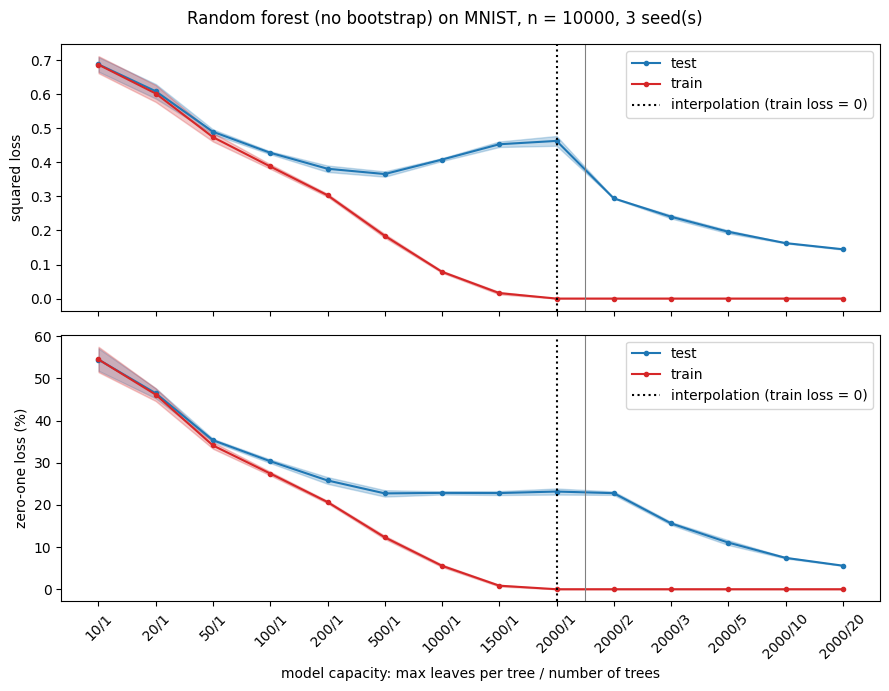

In [7]:
g = df.groupby(["leaves", "trees"])
xs = np.arange(len(order))
labels = [f"{L}/{T}" for L, T in order]
interp = next((i for i, k in enumerate(order) if g.train_mse.mean()[k] < 1e-8), None)

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
for ax, (test_col, train_col, ylab) in zip(axes, [("test_mse", "train_mse", "squared loss"),
                                                  ("test_err", "train_err", "zero-one loss (%)")]):
    for col, color, label in [(test_col, "C0", "test"), (train_col, "C3", "train")]:
        m = g[col].mean().reindex(order).values
        s = g[col].std().reindex(order).fillna(0).values
        ax.plot(xs, m, "o-", ms=3, color=color, label=label)
        ax.fill_between(xs, m - s, m + s, color=color, alpha=0.25)
    if interp is not None:
        ax.axvline(interp, color="k", ls=":", label="interpolation (train loss = 0)")
    ax.axvline(len(LEAVES) - 0.5, color="gray", lw=0.8)
    ax.set_ylabel(ylab); ax.legend()
axes[1].set_xticks(xs, labels, rotation=45)
axes[1].set_xlabel("model capacity: max leaves per tree / number of trees")
fig.suptitle(f"Random forest (no bootstrap) on MNIST, n = {N_TRAIN}, {df.seed.nunique()} seed(s)")
fig.tight_layout()
for ext in ["pdf", "png"]:
    fig.savefig(f"{DRIVE_DIR}/figures/forest_mnist_{TAG}.{ext}", dpi=150)
plt.show()